In [1]:

from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_engineering import create_features
from src.data_preprocessing import FEATURE_COLUMNS

df = pd.read_csv(
    PROJECT_ROOT / "data/raw/application_train.csv"
)

df = create_features(df)

X = df[FEATURE_COLUMNS]
y = df["TARGET"].astype(int)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

pipeline = joblib.load(
    PROJECT_ROOT / "models/xgboost.joblib"
)

print("Model loaded:", type(pipeline))


c:\Users\91882\OneDrive\Desktop\intelligent-credit-risk\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model loaded: <class 'sklearn.pipeline.Pipeline'>


In [2]:

preprocessor = pipeline.named_steps["preprocessing"]
classifier = pipeline.named_steps["classifier"]

# Use a manageable sample from validation data
X_sample = X_val.sample(
    n=min(200, len(X_val)),
    random_state=42
)

X_transformed = preprocessor.transform(X_sample)

# Convert sparse matrix if necessary
if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_sample.index
)

print("Transformed shape:", X_transformed_df.shape)

display(X_transformed_df.head())


Transformed shape: (200, 26)


,num__AMT_INCOME_TOTAL,num__AMT_CREDIT,num__AMT_ANNUITY,num__AGE_YEARS,num__EMPLOYMENT_YEARS,num__CREDIT_INCOME_RATIO,num__ANNUITY_INCOME_RATIO,num__ANNUITY_CREDIT_RATIO,num__EXT_SOURCE_1,num__EXT_SOURCE_2,...,cat__NAME_INCOME_TYPE_Student,cat__NAME_INCOME_TYPE_Unemployed,cat__NAME_INCOME_TYPE_Working,cat__NAME_EDUCATION_TYPE_Academic degree,cat__NAME_EDUCATION_TYPE_Higher education,cat__NAME_EDUCATION_TYPE_Incomplete higher,cat__NAME_EDUCATION_TYPE_Lower secondary,cat__NAME_EDUCATION_TYPE_Secondary / secondary special,cat__NAME_CONTRACT_TYPE_Cash loans,cat__NAME_CONTRACT_TYPE_Revolving loans
123055,-0.713984,-0.929371,-1.093282,1.716416,-0.283434,-0.543631,-0.592429,-0.163573,0.012412,0.276671,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
222164,-0.099054,-0.873542,-0.618775,-0.840010,0.846303,-0.890029,-0.696592,0.873261,0.012412,0.517276,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
191711,-0.140050,-0.864632,0.003261,1.057499,-0.779849,-0.864032,-0.035098,2.427822,0.012412,1.286371,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
111253,-0.918961,-0.634596,-0.755455,1.696033,-0.283434,0.423795,0.619278,-0.297590,0.120443,0.117033,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
54694,-0.918961,-0.761885,-1.112808,0.595317,-0.388212,0.140282,-0.195356,-0.720375,0.012412,0.549245,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [3]:

explainer = shap.TreeExplainer(classifier)

shap_values = explainer(X_transformed_df)

print("SHAP values shape:", shap_values.values.shape)


SHAP values shape: (200, 26)


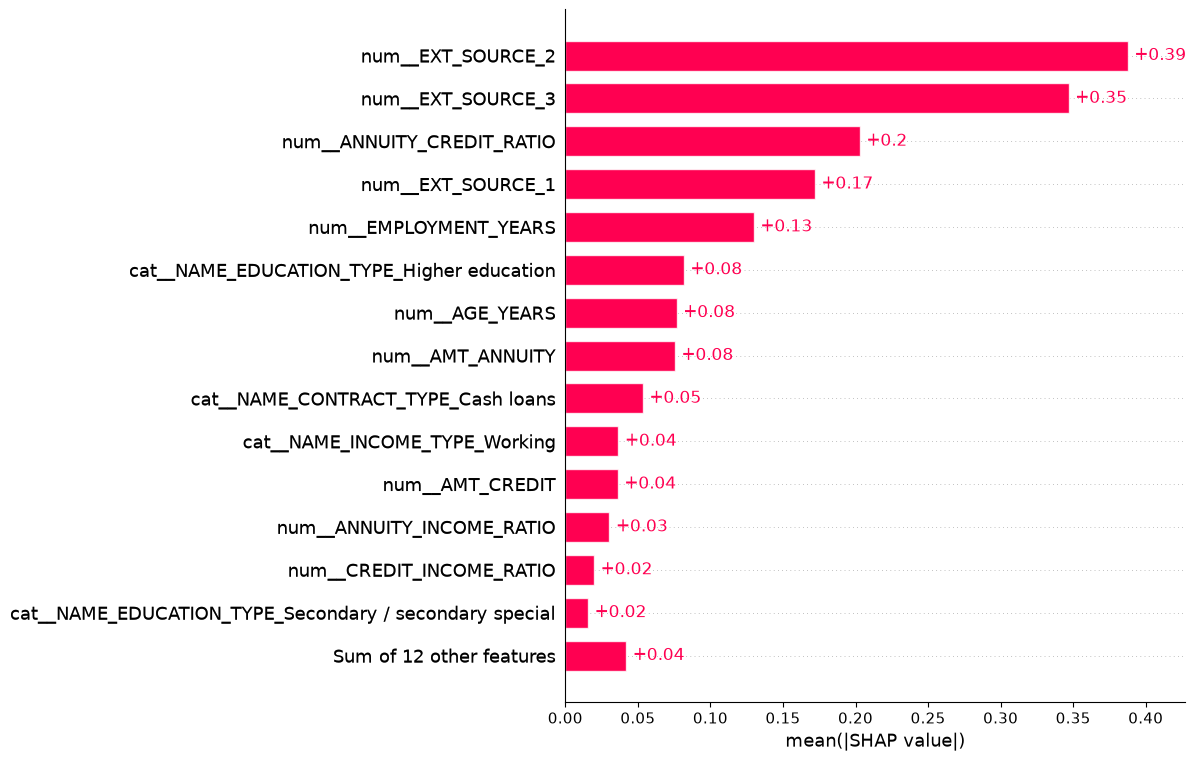

In [4]:

shap.plots.bar(
    shap_values,
    max_display=15,
    show=True
)


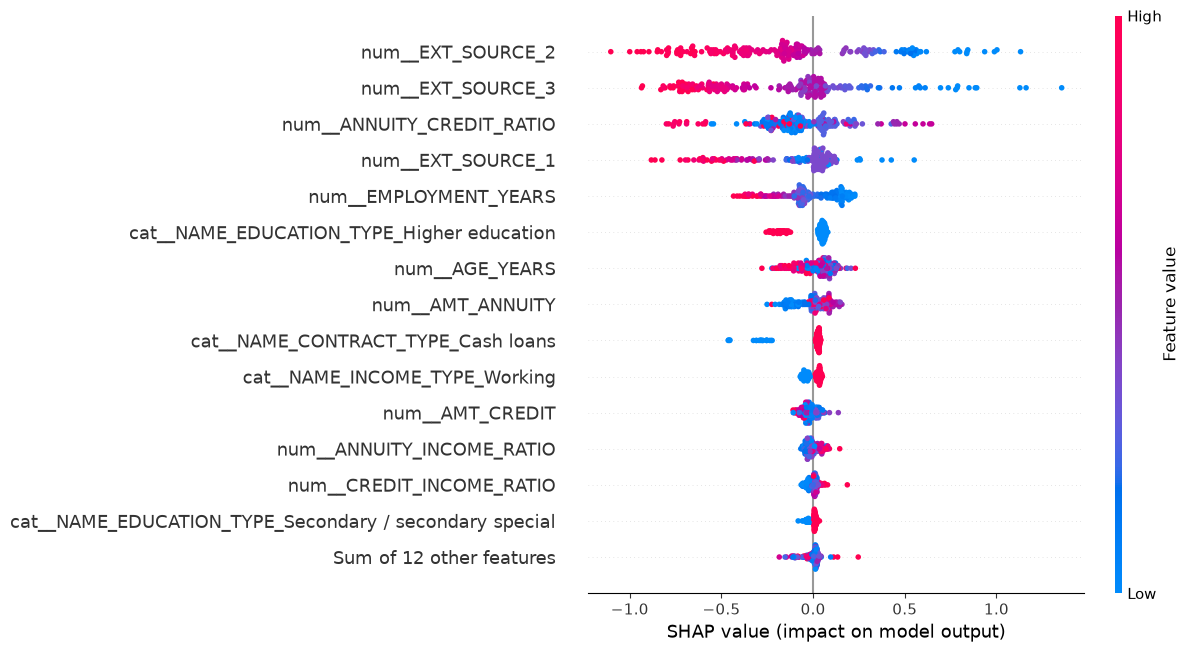

In [5]:

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=True
)


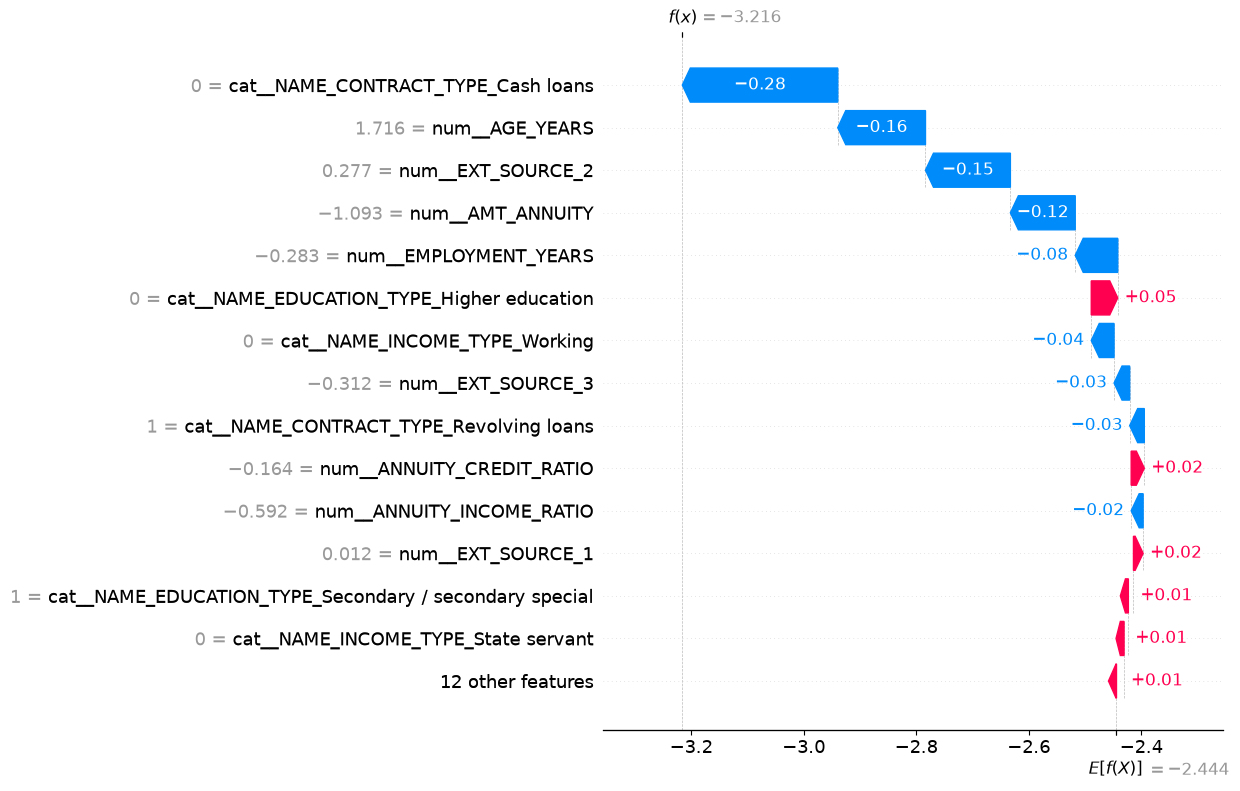

Predicted repayment difficulty probability: 3.86%


In [6]:

applicant_idx = 0

shap.plots.waterfall(
    shap_values[applicant_idx],
    max_display=15,
    show=True
)

predicted_pd_proxy = pipeline.predict_proba(
    X_sample.iloc[[applicant_idx]]
)[0, 1]

print(
    "Predicted repayment difficulty probability:",
    f"{predicted_pd_proxy:.2%}"
)


['num__CREDIT_INCOME_RATIO']


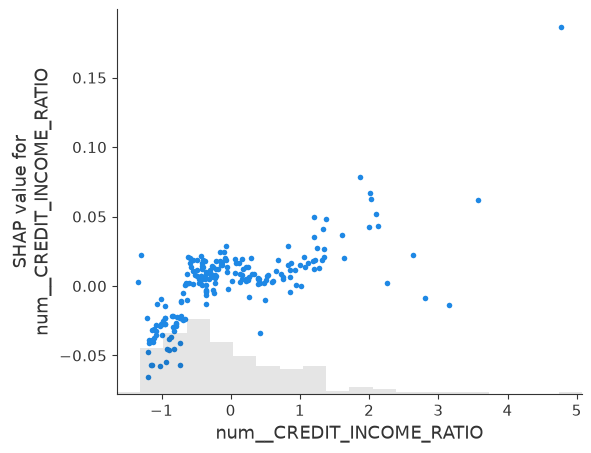

In [7]:

matches = [
    name for name in feature_names
    if "CREDIT_INCOME_RATIO" in name
]

print(matches)

if matches:
    shap.plots.scatter(
        shap_values[:, matches[0]],
        show=True
    )


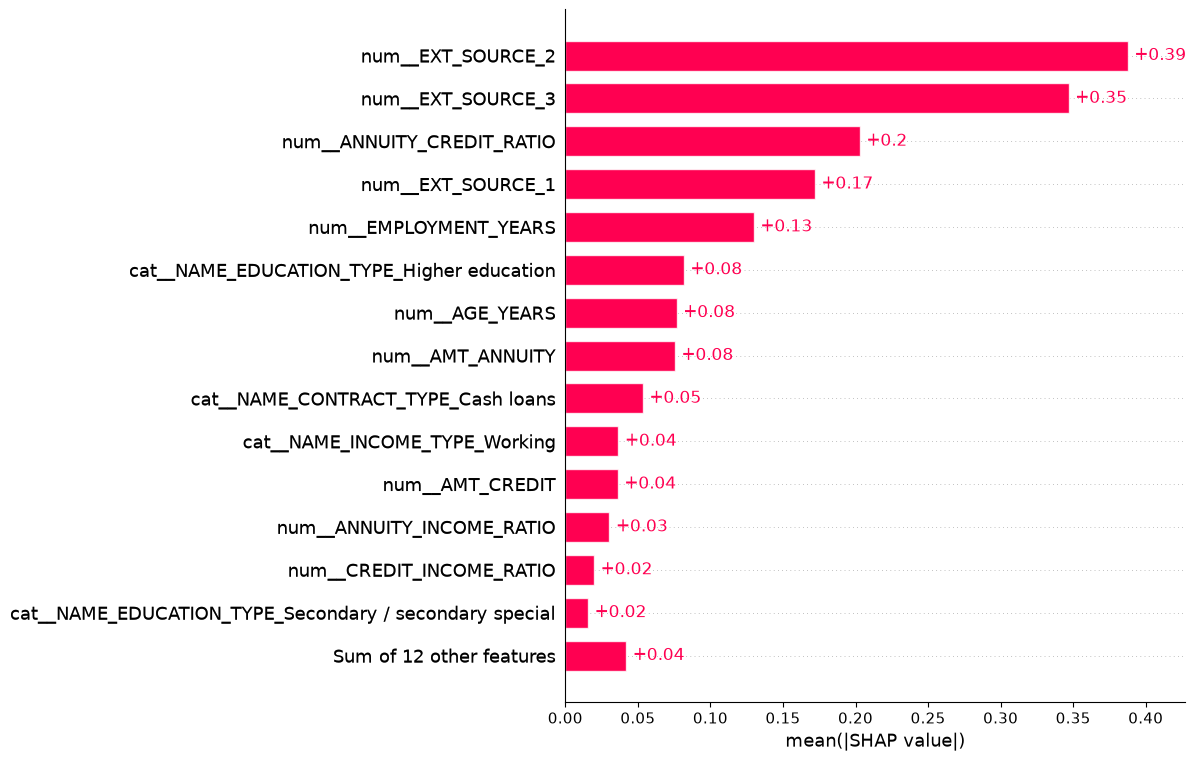

In [8]:

FIGURE_DIR = PROJECT_ROOT / "reports/figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.savefig(
    FIGURE_DIR / "shap_global_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
